In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move_special import *
import pygame
import matplotlib as mpl

pygame 2.6.1 (SDL 2.28.4, Python 3.13.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


/home/alepitt/Explorables/.venv/lib/python3.13/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


In [2]:
def read_parameters(file_path):
    params = {}

    # First pass: read and store values as strings
    with open(file_path, 'r') as file:
        for line in file:
            # Skip empty lines and comments (if any)
            line = line.strip()
            if line and not line.startswith('#'):
                # Split the line at the equals sign
                key, value = line.split('=')
                key = key.strip()
                value = value.strip()

                # Store the parameter as a string for now
                params[key] = value

    # Second pass: evaluate expressions and convert values
    for key, value in params.items():
        try:
            # Try to evaluate the value as a Python expression using previously defined parameters
            params[key] = eval(value, {}, params)
        except:
            # If it's not an expression, check if it can be converted to float or int
            if '.' in value:
                params[key] = float(value)
            else:
                params[key] = int(value)
        
        # Set the variable in the global namespace with the evaluated value
        globals()[key] = params[key]

    return params

In [3]:
parameters = read_parameters('main_parameters.txt')

for key, value in parameters.items():
    print(f"{key} = {value}")

n_special = 0
eta = 0.01
beta = 8.5
delta = 0.5

env = Ants_move_special(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                  beta_special, delta_special, tmax, n_special, t_transient)

n = 300
Lx = 32
Ly = 32
delta = 0.3
beta = 4.5
eta = 0.07
decay_rate = 0.015
eta_special = 0
delta_special = 0.3
beta_special = 4.5
n_special = 2
t_transient = 200
tmax = 1200


In [4]:
# create env
env.reset_objects()
pygame.init()

# set the color of the background
background_color = (255, 255, 255) 

# create the screen
screen_x, screen_y = 1000, 1000
screen_scale = screen_x/Lx

screen = pygame.display.set_mode((screen_x, screen_y)) 

# set the frame rate
FPS = 60
clock = pygame.time.Clock()

# simulation loop
running = True

pher_list = []
pos_list = []
head_list = []
M_list = []
avg_op_list = []

counter = 0   


while running:
    for event in pygame.event.get():
        if event.type == pygame.QUIT:
            running = False

    env.update()

    if env.t==t_transient:
        
        if n_special > 0:
            env.amount[env.n:] = env.eta_special
            # env.head[env.n:] = np.array( [env.directions[0] for _ in range(n_special)] )

    # env.pheromones[env.t%Lx, env.t%Lx] += eta*power

    pos_list.append(np.copy(env.positions))
    head_list.append(np.copy(env.head))
    pher_list.append(np.copy(env.pheromones))
    M_list.append(env.order_parameter_p())
    avg_op_list.append(np.mean(env.op_hist))
    
    # display env 
    screen.fill(background_color)
    env.draw(screen, screen_scale, 0.05)
    
    # update counter
    counter += 1

    if counter == (tmax):
        running = False

    # env.pheromones[env.t%Lx, env.t%Ly] += power*amount[0]

    # update display
    pygame.display.flip()
    # limit the frame rate
    clock.tick(FPS)

    print(counter, end='\r')
    
pygame.quit()

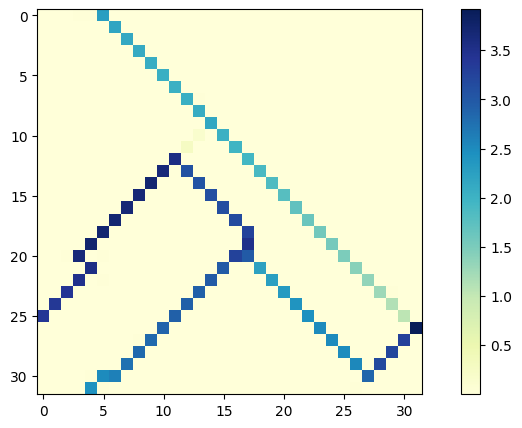

In [5]:
plt.figure(figsize=(10, 5))
plt.imshow(env.pheromones, cmap='YlGnBu')
plt.colorbar()

In [6]:
pos_list = np.array(pos_list)
head_list = np.array(head_list)
pher_list = np.array(pher_list)
avg_op_list = np.array(avg_op_list)

In [7]:
np.save('pos_list_ordered.npy', pos_list)
np.save('pher_list_ordered.npy', pher_list)

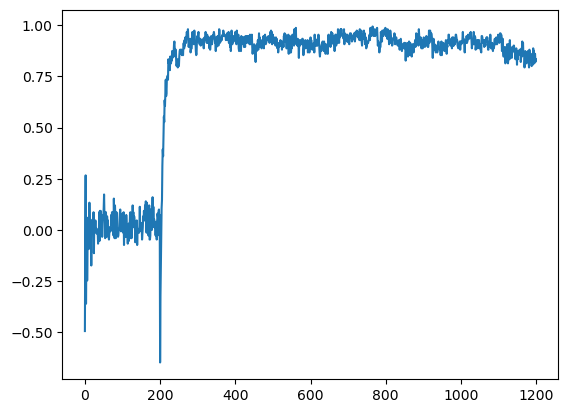

In [7]:
plt.plot(M_list)

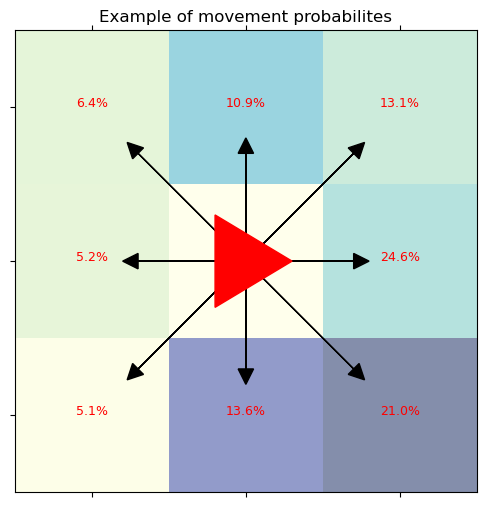

In [32]:
import numpy as np
import matplotlib.pyplot as plt

# Parametri
n = 3
center = (1,1)  # centro della griglia
heading = np.array([1,0]) # direzione Nord-Est (x=est, y=nord)

# Griglia valori casuali
np.random.seed(0)
values = np.random.rand(n,n)

# Funzione per calcolare l'angolo e la penalità
def angle_penalty(vec_target, heading):
    # normalizzazione
    ht = heading / np.linalg.norm(heading)
    vt = vec_target / np.linalg.norm(vec_target)
    # angolo tra heading e target
    dot = np.clip(np.dot(ht, vt), -1, 1)
    angle = np.arccos(dot)
    # penalità: 1 per avanti, cresce con l'angolo (pi = U-turn)
    penalty = 1 + (angle/np.pi)*3  # range 1..4
    return penalty

# Calcolo pesi con penalità
weights = np.zeros_like(values)
for i in range(n):
    for j in range(n):
        if (i,j) == center:
            continue
        vec = np.array([j-center[1], -(i-center[0])]) # coordinate (x,y)
        pen = angle_penalty(vec, heading)
        weights[i,j] = values[i,j]/pen

# Normalizzazione probabilità
probs = weights / weights.sum()

# Plot
fig, ax = plt.subplots(figsize=(6,6))
ax.matshow(values, cmap="YlGnBu", alpha=0.5)

# Disegno frecce e percentuali
for i in range(n):
    for j in range(n):
        # ax.text(j, i, f"{values[i,j]:.2f}", va='center', ha='center', fontsize=10)
        if (i,j) != center and probs[i,j] > 0:
            dx, dy = j-center[1], i-center[0]
            ax.arrow(center[1], center[0], dx*0.7, dy*0.7,
                     head_width=0.1, head_length=0.1, fc='k', ec='k')
            ax.text(j, i, f"{probs[i,j]*100:.1f}%", color="red",
                    ha="center", fontsize=9)

# Agente triangolare al centro
agent_x, agent_y = center[1], center[0]
triangle = plt.Polygon([[agent_x-0.2, agent_y-0.3], [agent_x+0.3, agent_y], [agent_x-0.2, agent_y+0.3]],
                       color='red')
ax.add_patch(triangle)

ax.set_xlim(-0.5,n-0.5)
ax.set_ylim(n-0.5,-0.5)
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.set_title("Example of movement probabilites")
plt.show()
